In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix 
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#pd.set_option('display.max_rows', 200)
%matplotlib widget

In [3]:
import glob
path = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/diffusion/pixel_size_5/reports/"
result_files = glob.glob(path + "/results_summary_*.csv")
df = pd.read_csv(result_files[0])

In [4]:
for file in result_files[1:]:
    df = pd.concat([df, pd.read_csv(file)], ignore_index=True)
df

,ID,cell_types,output,use_perfect_registration,use_perfect_segmentation,teaching_imprecision,canvas_size,mic_spacing,ms_spacing,cell_density,...,m/z 0,STD m/z 0,m/z 1,STD m/z 1,m/z 2,STD m/z 2,m/z 3,STD m/z 3,FPR,ARI
0,4867f93b-eaec-48cc-9807-e712fa58b4f4,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.017650,0.058935,0.079542,0.094837,0.117405,0.122135,0.347986,0.423278,0.0,0.717978
1,4ca8e297-26a2-4a50-bb13-4b386f9a79a8,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.019103,0.034137,0.136825,0.102240,0.204817,0.163126,0.396115,0.468463,0.0,0.765528
2,1e72161a-6e95-4e8c-94cd-0d6fa4c1bc33,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.017942,0.023304,0.177557,0.119757,0.258733,0.171744,0.505385,0.548009,0.0,0.835860
3,39bfd8b9-a7f6-4160-a866-9a58e8c24aa0,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.034506,0.083654,0.233570,0.150252,0.333379,0.185501,0.540830,0.559875,0.0,0.008479
4,72db0eff-42a3-439a-99f9-097d1d36a509,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.037116,0.060182,0.232648,0.171068,0.333080,0.229890,0.531400,0.578699,0.0,0.400773
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,44eb44ed-1e53-4b5a-b1a5-dc0df67a66a6,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.051494,0.050282,0.315314,0.195469,0.414089,0.248115,0.530376,0.572364,0.0,0.106833
105,854bdc39-c6bd-49de-a69c-3c1ba6429f26,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.057610,0.055762,0.339024,0.164611,0.427815,0.177192,0.541512,0.587136,0.0,0.045401
106,f76292f4-59ba-4b3c-b966-d7b30d3596c4,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.067751,0.065273,0.348464,0.199939,0.434992,0.225191,0.587765,0.628213,0.0,0.063136
107,f30f8ff9-6334-4510-b583-f4e9dc66e73a,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.010815,0.019347,0.010746,0.015218,0.013173,0.021726,0.040737,0.080167,0.0,0.929213


In [5]:
df.columns

Index(['ID', 'cell_types', 'output', 'use_perfect_registration',
       'use_perfect_segmentation', 'teaching_imprecision', 'canvas_size',
       'mic_spacing', 'ms_spacing', 'cell_density',
       'max_cell_placement_iterations', 'rotation', 'scale', 'mass_list',
       'seed', 'plot', 'save_img', 'remove_ambiguous', 'cell_diameter',
       'texture', 'texture_path', 'texture_epsilon_add',
       'texture_epsilon_multiply', 'diffusion_total_time', 'diffusion_dt',
       'diffusion_coeff', 'diffusion_barrier_alpha',
       'diffusion_leaky_outer_boundary', 'MRE X', 'STD MRE X', 'MRE Y',
       'STD MRE Y', 'm/z 0', 'STD m/z 0', 'm/z 1', 'STD m/z 1', 'm/z 2',
       'STD m/z 2', 'm/z 3', 'STD m/z 3', 'FPR', 'ARI'],
      dtype='str')

In [6]:
mean_diffusion = df.groupby('diffusion_total_time')[['diffusion_total_time', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].mean()
std_diffusion = df.groupby('diffusion_total_time')[['diffusion_total_time', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].std()

C:\Users\schwenzj\AppData\Local\Temp\ipykernel_8820\8194286.py:7: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  plt.errorbar(mean_diffusion['diffusion_total_time'], mean_diffusion[mz], yerr=std_diffusion[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)


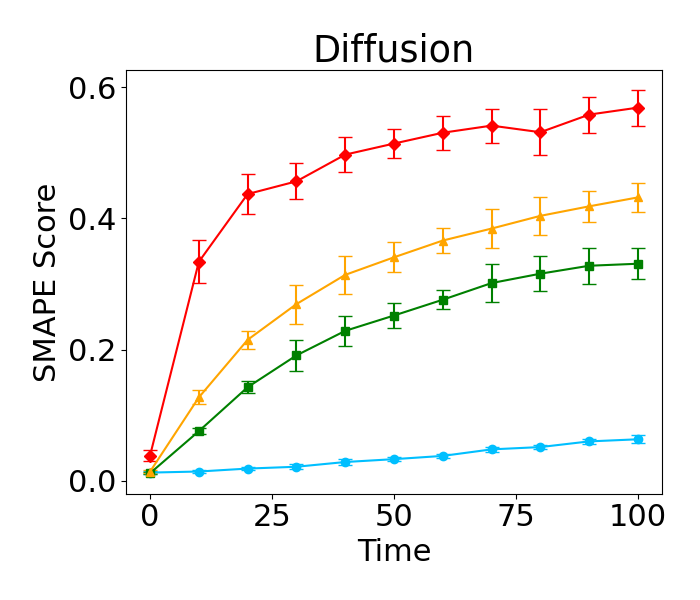

In [9]:
plt.rcParams.update({'font.size': 22})
colors = ['deepskyblue', 'green', 'orange', 'red']
markers = ['o', 's', '^', 'D']
labels = ['\"PE(36:2)\"', '\"PC(34:1)\"', '\"TG(54:3)\"', '\"Cholesterol\"']
plt.figure(figsize=(7,6))
for i, mz in enumerate(['m/z 0', 'm/z 1', 'm/z 2', 'm/z 3']):
    plt.errorbar(mean_diffusion['diffusion_total_time'], mean_diffusion[mz], yerr=std_diffusion[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)
plt.xlabel('Time')
plt.ylabel('SMAPE Score')
plt.title('Diffusion')
plt.tight_layout()
#plt.legend()
plt.tight_layout()
plt.savefig(path + "evaluation/diffusion_total_time_results.png", dpi=600)
plt.show()

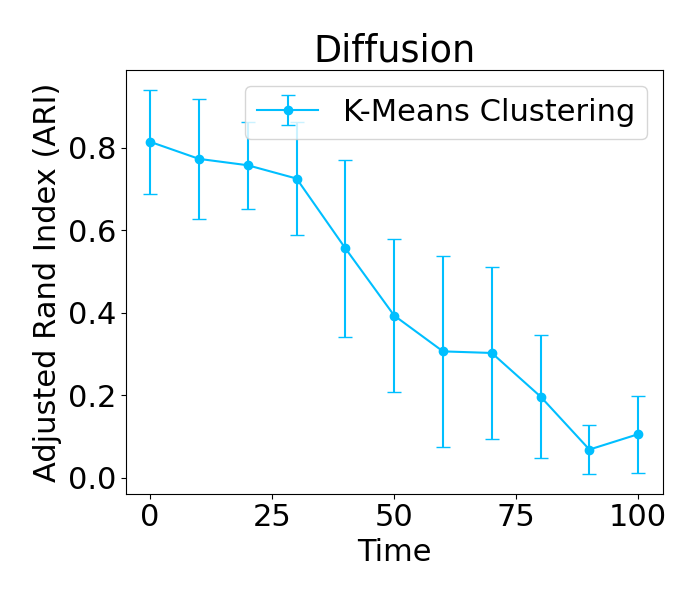

In [10]:
plt.figure(figsize=(7,6))
plt.errorbar(mean_diffusion['diffusion_total_time'], mean_diffusion['ARI'], yerr=std_diffusion['ARI'], label='K-Means Clustering', color=colors[0], fmt='o-', capsize=5)
plt.xlabel('Time')
plt.ylabel('Adjusted Rand Index (ARI)')
plt.title('Diffusion')
plt.legend()
plt.tight_layout()
plt.savefig(path + "evaluation/diffusion_total_time_ARI_results.png", dpi=600)
plt.show()